In [1]:
!pip -q install datasets scikit-learn

In [2]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import random, math, os
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

dataset = load_dataset(
    "IB-Emper/hinglish-translit-sarvam",
    split="train",
    streaming=True
).shuffle(seed=SEED, buffer_size=10000)

records = []
for row in dataset:
    if row.get("kind") == "word" and row.get("roman") and row.get("devanagari"):
        records.append((row["roman"].strip(), row["devanagari"].strip()))
    if len(records) >= 5000:
        break

df = pd.DataFrame(records, columns=["roman", "devanagari"])
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(df.head())
print("Total examples:", len(df))

Device: cpu


README.md:   0%|          | 0.00/3.71k [00:00<?, ?B/s]

      roman devanagari
0  vipkshih    विपक्षी
1    bangel      बंगाल
2     pitaa       पिता
3     pruar     प्रयोग
4      sakk       सके।
Total examples: 5000


In [3]:
train_df, temp_df = train_test_split(df, test_size=0.20, random_state=SEED)
valid_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)

train_pairs = list(zip(train_df.roman, train_df.devanagari))
valid_pairs = list(zip(valid_df.roman, valid_df.devanagari))
test_pairs = list(zip(test_df.roman, test_df.devanagari))

print("Training:", len(train_pairs))
print("Validation:", len(valid_pairs))
print("Testing:", len(test_pairs))

Training: 4000
Validation: 500
Testing: 500


In [4]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3

src_vocab = {"<pad>": PAD, "<sos>": SOS, "<eos>": EOS, "<unk>": UNK}
tgt_vocab = {"<pad>": PAD, "<sos>": SOS, "<eos>": EOS, "<unk>": UNK}

for roman, _ in train_pairs:
    for ch in roman:
        if ch not in src_vocab:
            src_vocab[ch] = len(src_vocab)

for _, hindi in train_pairs:
    for ch in hindi:
        if ch not in tgt_vocab:
            tgt_vocab[ch] = len(tgt_vocab)

src_ivocab = {v: k for k, v in src_vocab.items()}
tgt_ivocab = {v: k for k, v in tgt_vocab.items()}

def encode_src(text):
    return [src_vocab.get(ch, UNK) for ch in text]

def encode_tgt(text):
    return [SOS] + [tgt_vocab.get(ch, UNK) for ch in text] + [EOS]

class HindiDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, index):
        x, y = self.pairs[index]
        return torch.tensor(encode_src(x)), torch.tensor(encode_tgt(y)), x, y

def collate_fn(batch):
    xs, ys, raw_x, raw_y = zip(*batch)
    X = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=PAD)
    Y = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD)
    return X, Y, list(raw_x), list(raw_y)

train_loader = DataLoader(HindiDataset(train_pairs), batch_size=64, shuffle=True, collate_fn=collate_fn)
valid_loader = DataLoader(HindiDataset(valid_pairs), batch_size=64, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(HindiDataset(test_pairs), batch_size=64, shuffle=False, collate_fn=collate_fn)

print("Input vocabulary:", len(src_vocab), "| Output vocabulary:", len(tgt_vocab))

Input vocabulary: 30 | Output vocabulary: 66


In [5]:
class Seq2Seq(nn.Module):
    def __init__(self, cell="GRU", emb=64, hidden=128):
        super().__init__()
        self.cell = cell.upper()
        self.src_emb = nn.Embedding(len(src_vocab), emb, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(len(tgt_vocab), emb, padding_idx=PAD)
        rnn_class = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[self.cell]
        self.encoder = rnn_class(emb, hidden, batch_first=True)
        self.decoder = rnn_class(emb, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, len(tgt_vocab))

    def forward(self, X, Y=None, max_len=30):
        _, state = self.encoder(self.src_emb(X))
        token = torch.full((X.size(0), 1), SOS, dtype=torch.long, device=X.device)
        steps = Y.size(1) - 1 if Y is not None else max_len
        outputs = []
        for t in range(steps):
            out, state = self.decoder(self.tgt_emb(token), state)
            logits = self.fc(out[:, -1, :])
            outputs.append(logits)
            if Y is not None:
                token = Y[:, t+1:t+2]
            else:
                token = logits.argmax(-1, keepdim=True)
        return torch.stack(outputs, dim=1)

    @torch.no_grad()
    def predict(self, X, max_len=30):
        self.eval()
        logits = self.forward(X, max_len=max_len)
        results = []
        for row in logits.argmax(-1):
            chars = []
            for idx in row.tolist():
                if idx == EOS:
                    break
                if idx not in (PAD, SOS):
                    chars.append(tgt_ivocab.get(idx, ""))
            results.append("".join(chars))
        return results

In [6]:
def evaluate(model, loader):
    model.eval()
    correct, total, loss_total = 0, 0, 0.0
    criterion = nn.CrossEntropyLoss(ignore_index=PAD)
    with torch.no_grad():
        for X, Y, raw_x, raw_y in loader:
            X, Y = X.to(DEVICE), Y.to(DEVICE)
            logits = model(X, Y)
            target = Y[:, 1:1 + logits.size(1)]
            loss = criterion(logits.reshape(-1, logits.size(-1)), target.reshape(-1))
            loss_total += loss.item() * X.size(0)
            predictions = model.predict(X)
            for pred, actual in zip(predictions, raw_y):
                correct += int(pred == actual)
                total += 1
    return loss_total / max(total, 1), correct / max(total, 1)

def train_model(model, epochs=15, lr=0.001):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD)
    history = []
    best_accuracy = -1.0
    best_state = None

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for X, Y, _, _ in train_loader:
            X, Y = X.to(DEVICE), Y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(X, Y)
            target = Y[:, 1:1 + logits.size(1)]
            loss = criterion(logits.reshape(-1, logits.size(-1)), target.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running_loss += loss.item() * X.size(0)

        val_loss, val_acc = evaluate(model, valid_loader)
        history.append({
            "epoch": epoch + 1,
            "train_loss": running_loss / len(train_loader.dataset),
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {history[-1]['train_loss']:.4f} | "
              f"Val Loss: {val_loss:.4f} | Validation Exact-Match Accuracy: {val_acc:.4f}")

        if val_acc > best_accuracy:
            best_accuracy = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

def plot_history(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history["epoch"], history["train_loss"], marker="o", label="Train loss")
    plt.plot(history["epoch"], history["val_loss"], marker="s", label="Validation loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(title + " - Loss")
    plt.legend(); plt.grid(True); plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(history["epoch"], history["val_accuracy"], marker="o", label="Validation exact-match accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(title + " - Validation Accuracy")
    plt.legend(); plt.grid(True); plt.show()

\nTraining RNN
Epoch 1/15 | Train Loss: 3.2101 | Val Loss: 2.8522 | Validation Exact-Match Accuracy: 0.0000
Epoch 2/15 | Train Loss: 2.7430 | Val Loss: 2.7038 | Validation Exact-Match Accuracy: 0.0000
Epoch 3/15 | Train Loss: 2.6168 | Val Loss: 2.6169 | Validation Exact-Match Accuracy: 0.0000
Epoch 4/15 | Train Loss: 2.5320 | Val Loss: 2.5571 | Validation Exact-Match Accuracy: 0.0000
Epoch 5/15 | Train Loss: 2.4557 | Val Loss: 2.5132 | Validation Exact-Match Accuracy: 0.0000
Epoch 6/15 | Train Loss: 2.3988 | Val Loss: 2.4767 | Validation Exact-Match Accuracy: 0.0000
Epoch 7/15 | Train Loss: 2.3534 | Val Loss: 2.4269 | Validation Exact-Match Accuracy: 0.0000
Epoch 8/15 | Train Loss: 2.3106 | Val Loss: 2.4089 | Validation Exact-Match Accuracy: 0.0000
Epoch 9/15 | Train Loss: 2.2734 | Val Loss: 2.3676 | Validation Exact-Match Accuracy: 0.0000
Epoch 10/15 | Train Loss: 2.2283 | Val Loss: 2.3674 | Validation Exact-Match Accuracy: 0.0000
Epoch 11/15 | Train Loss: 2.1820 | Val Loss: 2.3148 | 

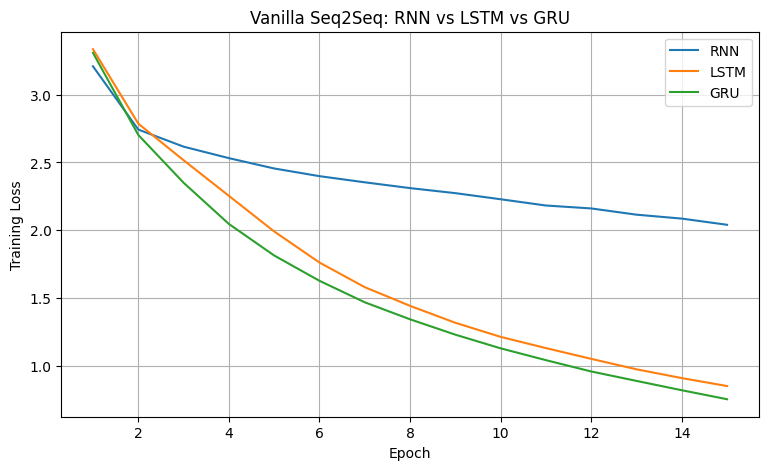

In [7]:
# Train vanilla Seq2Seq with RNN, LSTM, and GRU
models = {}
histories = {}

for cell_type in ["RNN", "LSTM", "GRU"]:
    print("\\nTraining", cell_type)
    model = Seq2Seq(cell=cell_type, emb=64, hidden=128)
    model, history = train_model(model, epochs=15, lr=0.001)
    models[cell_type] = model
    histories[cell_type] = history

plt.figure(figsize=(9, 5))
for name, history in histories.items():
    plt.plot(history["epoch"], history["train_loss"], label=name)
plt.xlabel("Epoch"); plt.ylabel("Training Loss")
plt.title("Vanilla Seq2Seq: RNN vs LSTM vs GRU")
plt.legend(); plt.grid(True); plt.show()

## Attention Seq2Seq

Epoch 1/20 | Train Loss: 3.1772 | Val Loss: 2.6736 | Validation Exact-Match Accuracy: 0.0020
Epoch 2/20 | Train Loss: 2.2723 | Val Loss: 1.9602 | Validation Exact-Match Accuracy: 0.0360
Epoch 3/20 | Train Loss: 1.8604 | Val Loss: 1.7752 | Validation Exact-Match Accuracy: 0.0420
Epoch 4/20 | Train Loss: 1.6782 | Val Loss: 1.6449 | Validation Exact-Match Accuracy: 0.0820
Epoch 5/20 | Train Loss: 1.5831 | Val Loss: 1.6553 | Validation Exact-Match Accuracy: 0.0960
Epoch 6/20 | Train Loss: 1.5080 | Val Loss: 1.5742 | Validation Exact-Match Accuracy: 0.1080
Epoch 7/20 | Train Loss: 1.4559 | Val Loss: 1.4999 | Validation Exact-Match Accuracy: 0.1200
Epoch 8/20 | Train Loss: 1.4015 | Val Loss: 1.4674 | Validation Exact-Match Accuracy: 0.1160
Epoch 9/20 | Train Loss: 1.3193 | Val Loss: 1.5110 | Validation Exact-Match Accuracy: 0.1340
Epoch 10/20 | Train Loss: 1.2972 | Val Loss: 1.4135 | Validation Exact-Match Accuracy: 0.1300
Epoch 11/20 | Train Loss: 1.2365 | Val Loss: 1.4825 | Validation Exac

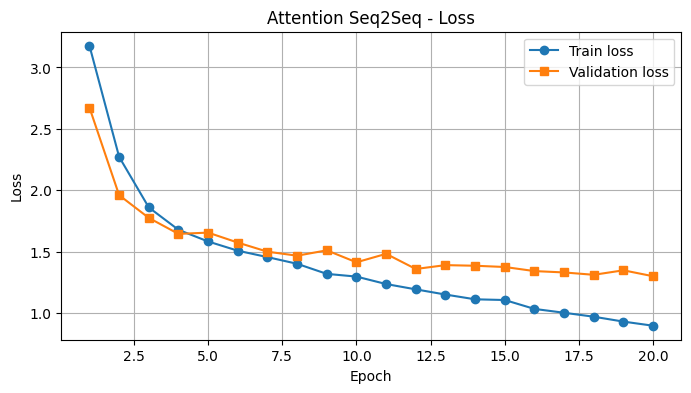

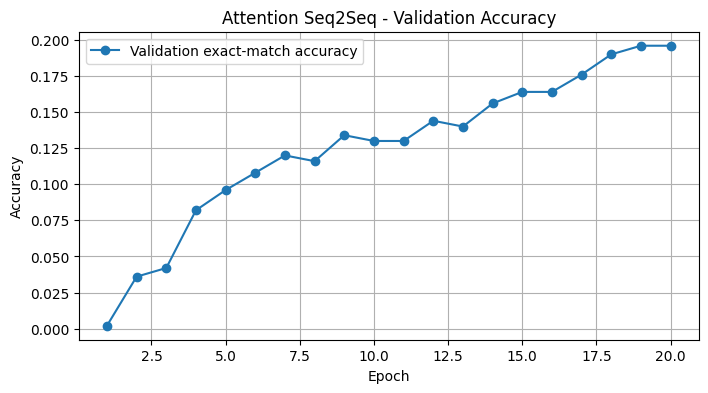

In [8]:
class AttentionSeq2Seq(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, emb_dim=64, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.src_emb = nn.Embedding(src_vocab_size, emb_dim, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_vocab_size, emb_dim, padding_idx=PAD)
        self.encoder = nn.GRU(emb_dim, hidden_dim, batch_first=True)
        self.decoder = nn.GRU(emb_dim + hidden_dim, hidden_dim, batch_first=True)
        self.attn_enc = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.attn_dec = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.attn_score = nn.Linear(hidden_dim, 1, bias=False)
        self.output_layer = nn.Linear(hidden_dim * 2, tgt_vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, tgt=None, teacher_forcing=0.5, max_len=30, return_attention=False):
        mask = src.ne(PAD)
        enc_out, hidden = self.encoder(self.dropout(self.src_emb(src)))
        token = torch.full((src.size(0), 1), SOS, dtype=torch.long, device=src.device)
        steps = tgt.size(1) - 1 if tgt is not None else max_len
        outputs, attention_weights = [], []

        for t in range(steps):
            query = hidden[-1].unsqueeze(1)
            scores = self.attn_score(torch.tanh(self.attn_enc(enc_out) + self.attn_dec(query))).squeeze(-1)
            scores = scores.masked_fill(~mask, -1e9)
            weights = torch.softmax(scores, dim=-1)
            context = torch.bmm(weights.unsqueeze(1), enc_out)
            embedded = self.dropout(self.tgt_emb(token))
            decoder_input = torch.cat([embedded, context], dim=-1)
            dec_out, hidden = self.decoder(decoder_input, hidden)
            logits = self.output_layer(torch.cat([dec_out, context], dim=-1).squeeze(1))
            outputs.append(logits)
            attention_weights.append(weights)

            if tgt is not None and random.random() < teacher_forcing:
                token = tgt[:, t+1:t+2]
            else:
                token = logits.argmax(-1, keepdim=True)

        logits = torch.stack(outputs, dim=1)
        if return_attention:
            return logits, torch.stack(attention_weights, dim=1)
        return logits

    @torch.no_grad()
    def predict_ids(self, src, max_len=30):
        self.eval()
        logits = self.forward(src, max_len=max_len)
        predictions = []
        for row in logits.argmax(-1):
            sequence = []
            for idx in row.tolist():
                if idx == EOS:
                    break
                if idx not in (PAD, SOS):
                    sequence.append(idx)
            predictions.append(sequence)
        return predictions

    @torch.no_grad()
    def predict(self, src, max_len=30):
        sequences = self.predict_ids(src, max_len=max_len)
        return ["".join(tgt_ivocab.get(int(idx), "") for idx in seq) for seq in sequences]

attention_model = AttentionSeq2Seq(len(src_vocab), len(tgt_vocab), emb_dim=64, hidden_dim=128, dropout=0.2).to(DEVICE)
attention_model, attention_history = train_model(attention_model, epochs=20, lr=0.001)
torch.save(attention_model.state_dict(), "best_attention.pt")
plot_history(attention_history, "Attention Seq2Seq")

## Manual Transformer (no `nn.Transformer` / `nn.TransformerEncoder`)

Epoch 1/20 | Train Loss: 3.3976 | Val Loss: 2.9389 | Validation Exact-Match Accuracy: 0.0000
Epoch 2/20 | Train Loss: 2.6911 | Val Loss: 2.3390 | Validation Exact-Match Accuracy: 0.0000
Epoch 3/20 | Train Loss: 2.2149 | Val Loss: 1.9576 | Validation Exact-Match Accuracy: 0.0200
Epoch 4/20 | Train Loss: 1.9087 | Val Loss: 1.7242 | Validation Exact-Match Accuracy: 0.0480
Epoch 5/20 | Train Loss: 1.7182 | Val Loss: 1.5966 | Validation Exact-Match Accuracy: 0.0620
Epoch 6/20 | Train Loss: 1.5978 | Val Loss: 1.5019 | Validation Exact-Match Accuracy: 0.0840
Epoch 7/20 | Train Loss: 1.5101 | Val Loss: 1.4451 | Validation Exact-Match Accuracy: 0.0860
Epoch 8/20 | Train Loss: 1.4361 | Val Loss: 1.4081 | Validation Exact-Match Accuracy: 0.0900
Epoch 9/20 | Train Loss: 1.3860 | Val Loss: 1.3624 | Validation Exact-Match Accuracy: 0.1060
Epoch 10/20 | Train Loss: 1.3394 | Val Loss: 1.3192 | Validation Exact-Match Accuracy: 0.1080
Epoch 11/20 | Train Loss: 1.3077 | Val Loss: 1.3021 | Validation Exac

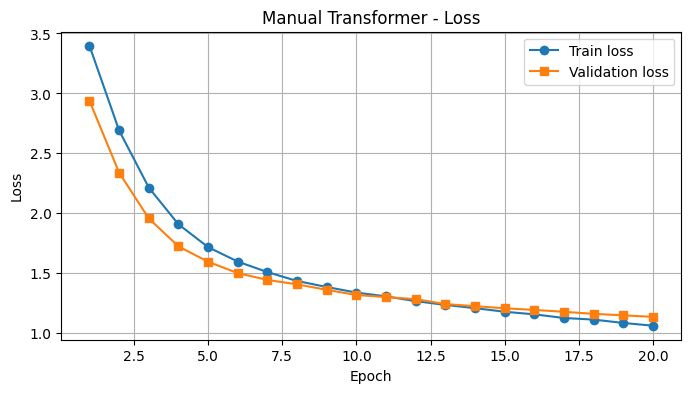

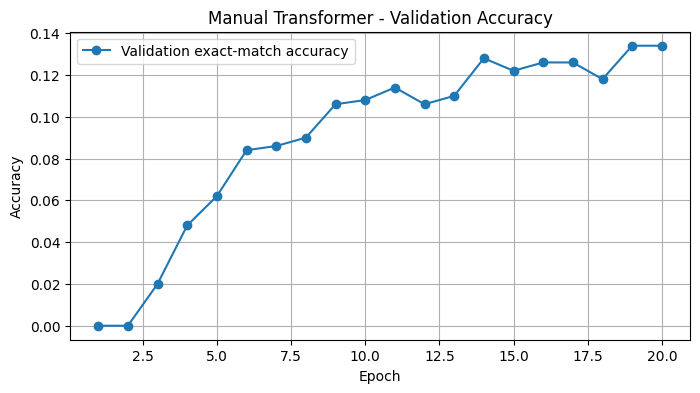

In [9]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model=64, max_len=256):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(max_len).float().unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[:pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        if x.size(1) > self.pe.size(1):
            raise ValueError("Input sequence exceeds max_len.")
        return x + self.pe[:, :x.size(1)]

class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model=64, nhead=4, ff_dim=256, dropout=0.1):
        super().__init__()
        self.attention = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, ff_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(ff_dim, d_model))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, padding_mask):
        attn_out, _ = self.attention(x, x, x, key_padding_mask=padding_mask, need_weights=False)
        x = self.norm1(x + self.dropout(attn_out))
        return self.norm2(x + self.dropout(self.ffn(x)))

class TransformerDecoderBlock(nn.Module):
    def __init__(self, d_model=64, nhead=4, ff_dim=256, dropout=0.1):
        super().__init__()
        self.self_attention = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.cross_attention = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm1, self.norm2, self.norm3 = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, ff_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(ff_dim, d_model))
        self.dropout = nn.Dropout(dropout)
    def forward(self, tgt, memory, tgt_mask, src_mask):
        length = tgt.size(1)
        causal_mask = torch.triu(torch.ones(length, length, dtype=torch.bool, device=tgt.device), diagonal=1)
        attn_out, _ = self.self_attention(tgt, tgt, tgt, attn_mask=causal_mask, key_padding_mask=tgt_mask, need_weights=False)
        tgt = self.norm1(tgt + self.dropout(attn_out))
        attn_out, _ = self.cross_attention(tgt, memory, memory, key_padding_mask=src_mask, need_weights=False)
        tgt = self.norm2(tgt + self.dropout(attn_out))
        return self.norm3(tgt + self.dropout(self.ffn(tgt)))

class ManualTransformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model=64, nhead=4, ff_dim=256, dropout=0.1):
        super().__init__()
        self.src_emb = nn.Embedding(src_vocab_size, d_model, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_vocab_size, d_model, padding_idx=PAD)
        self.src_bn = nn.BatchNorm1d(d_model)
        self.tgt_bn = nn.BatchNorm1d(d_model)
        self.position = PositionalEncoding(d_model)
        self.encoder = TransformerEncoderBlock(d_model, nhead, ff_dim, dropout)
        self.decoder = TransformerDecoderBlock(d_model, nhead, ff_dim, dropout)
        self.output_layer = nn.Linear(d_model, tgt_vocab_size)
        self.d_model = d_model
    def apply_bn(self, x, bn):
        return bn(x.transpose(1, 2)).transpose(1, 2)
    def encode(self, src):
        src_mask = src.eq(PAD)
        x = self.position(self.apply_bn(self.src_emb(src) * math.sqrt(self.d_model), self.src_bn))
        return self.encoder(x, src_mask), src_mask
    def forward(self, src, tgt=None, teacher_forcing=0.5, max_len=30):
        memory, src_mask = self.encode(src)
        if tgt is not None:
            decoder_input = tgt[:, :-1]
            y = self.position(self.apply_bn(self.tgt_emb(decoder_input) * math.sqrt(self.d_model), self.tgt_bn))
            decoded = self.decoder(y, memory, decoder_input.eq(PAD), src_mask)
            return self.output_layer(decoded)
        token = torch.full((src.size(0), 1), SOS, dtype=torch.long, device=src.device)
        outputs = []
        finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        for _ in range(max_len):
            y = self.position(self.apply_bn(self.tgt_emb(token) * math.sqrt(self.d_model), self.tgt_bn))
            decoded = self.decoder(y, memory, token.eq(PAD), src_mask)
            logits = self.output_layer(decoded[:, -1, :])
            outputs.append(logits)
            next_token = logits.argmax(-1, keepdim=True)
            next_token[finished] = EOS
            finished |= next_token.squeeze(1).eq(EOS)
            token = torch.cat([token, next_token], dim=1)
            if finished.all():
                break
        return torch.stack(outputs, dim=1)
    @torch.no_grad()
    def predict_ids(self, src, max_len=30):
        self.eval()
        logits = self.forward(src, max_len=max_len)
        predictions = []
        for row in logits.argmax(-1):
            seq = []
            for idx in row.tolist():
                if idx == EOS:
                    break
                if idx not in (PAD, SOS):
                    seq.append(idx)
            predictions.append(seq)
        return predictions
    @torch.no_grad()
    def predict(self, src, max_len=30):
        sequences = self.predict_ids(src, max_len=max_len)
        return ["".join(tgt_ivocab.get(int(idx), "") for idx in seq) for seq in sequences]

transformer_model = ManualTransformer(len(src_vocab), len(tgt_vocab), d_model=64, nhead=4, ff_dim=256, dropout=0.1).to(DEVICE)
transformer_model, transformer_history = train_model(transformer_model, epochs=20, lr=0.0005)
torch.save(transformer_model.state_dict(), "best_transformer.pt")
plot_history(transformer_history, "Manual Transformer")

## Test-set evaluation and prediction exports

Vanilla RNN: 1/500 exact matches = 0.20%
Vanilla LSTM: 73/500 exact matches = 14.60%
Vanilla GRU: 78/500 exact matches = 15.60%
Attention Seq2Seq: 93/500 exact matches = 18.60%
Manual Transformer: 81/500 exact matches = 16.20%


,Model,Test Exact-Match Accuracy (%)
0,Vanilla RNN,0.2
1,Vanilla LSTM,14.6
2,Vanilla GRU,15.6
3,Attention Seq2Seq,18.6
4,Manual Transformer,16.2


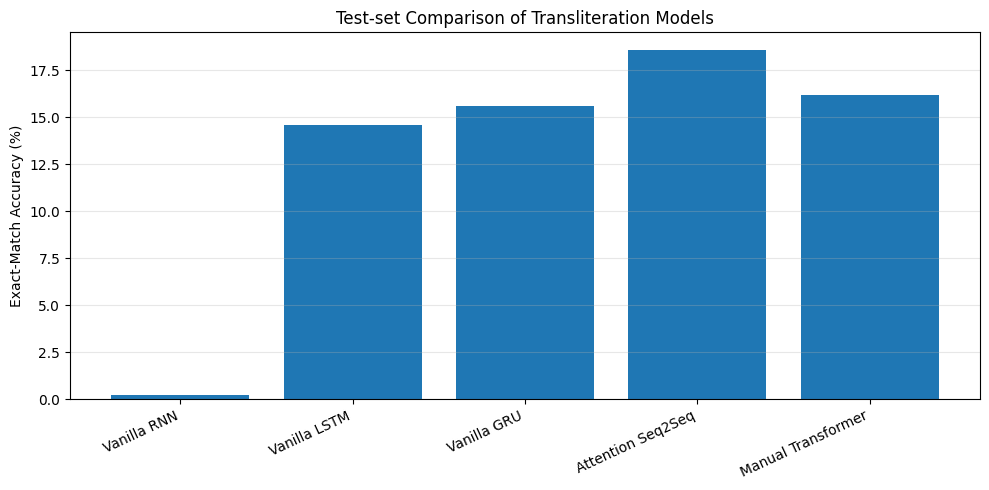

Saved predictions in predictions_vanilla/, predictions_attention/, and predictions_transformers/.


In [10]:
def decode_ids(ids, inverse_vocab):
    chars = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS:
            break
        if idx not in (PAD, SOS):
            chars.append(inverse_vocab.get(idx, ""))
    return "".join(chars)

def evaluate_test_model(model, data_loader, model_name):
    model.eval()
    rows, correct, total = [], 0, 0
    with torch.no_grad():
        for X, Y, raw_x, raw_y in data_loader:
            X, Y = X.to(DEVICE), Y.to(DEVICE)
            predictions = model.predict(X)
            for roman, actual, predicted in zip(raw_x, raw_y, predictions):
                ok = predicted == actual
                correct += int(ok)
                total += 1
                rows.append({
                    "Model": model_name,
                    "Romanized Input": roman,
                    "Actual Hindi": actual,
                    "Predicted Hindi": predicted,
                    "Correct": ok
                })
    accuracy = correct / total if total else 0.0
    print(f"{model_name}: {correct}/{total} exact matches = {accuracy*100:.2f}%")
    return accuracy, pd.DataFrame(rows)

test_scores = {}
all_results = {}
for name, model in models.items():
    score, result = evaluate_test_model(model, test_loader, f"Vanilla {name}")
    test_scores[f"Vanilla {name}"] = score
    all_results[f"Vanilla {name}"] = result

attention_accuracy, attention_results = evaluate_test_model(attention_model, test_loader, "Attention Seq2Seq")
transformer_accuracy, transformer_results = evaluate_test_model(transformer_model, test_loader, "Manual Transformer")
test_scores["Attention Seq2Seq"] = attention_accuracy
test_scores["Manual Transformer"] = transformer_accuracy
all_results["Attention Seq2Seq"] = attention_results
all_results["Manual Transformer"] = transformer_results

os.makedirs("predictions_vanilla", exist_ok=True)
os.makedirs("predictions_attention", exist_ok=True)
os.makedirs("predictions_transformers", exist_ok=True)

for name, result in all_results.items():
    if name.startswith("Vanilla"):
        filename = name.lower().replace(" ", "_") + ".csv"
        result.to_csv(os.path.join("predictions_vanilla", filename), index=False)

attention_results.to_csv("predictions_attention/predictions.csv", index=False)
transformer_results.to_csv("predictions_transformers/predictions.csv", index=False)

comparison = pd.DataFrame([
    {"Model": name, "Test Exact-Match Accuracy (%)": score * 100}
    for name, score in test_scores.items()
])
display(comparison)

plt.figure(figsize=(10, 5))
plt.bar(comparison["Model"], comparison["Test Exact-Match Accuracy (%)"])
plt.ylabel("Exact-Match Accuracy (%)")
plt.title("Test-set Comparison of Transliteration Models")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Saved predictions in predictions_vanilla/, predictions_attention/, and predictions_transformers/.")

In [11]:
# Inspect incorrect predictions for error analysis
display(attention_results[attention_results["Correct"] == False].head(20))
display(transformer_results[transformer_results["Correct"] == False].head(20))

,Model,Romanized Input,Actual Hindi,Predicted Hindi,Correct
0,Attention Seq2Seq,bale,भले,बलले,False
1,Attention Seq2Seq,kaayuni,कानूनी,कायुनी,False
2,Attention Seq2Seq,hona,होनी,होना,False
3,Attention Seq2Seq,ank,अंक,अनकक,False
4,Attention Seq2Seq,samsaar,सिफारिश,समसर,False
5,Attention Seq2Seq,mabbat,मतलब,मबबात,False
6,Attention Seq2Seq,maanmohan,मनमोहन,मंमून,False
7,Attention Seq2Seq,ooot,आउट,ऑटट,False
8,Attention Seq2Seq,tournemant,टूर्नामेंट,तूर्मान,False
9,Attention Seq2Seq,cannel,चैनल,कनेल,False


,Model,Romanized Input,Actual Hindi,Predicted Hindi,Correct
0,Manual Transformer,bale,भले,बले,False
1,Manual Transformer,kaayuni,कानूनी,कायानी,False
2,Manual Transformer,hona,होनी,हों,False
3,Manual Transformer,ank,अंक,आनक,False
4,Manual Transformer,samsaar,सिफारिश,समसर,False
5,Manual Transformer,mabbat,मतलब,मबाबत,False
6,Manual Transformer,maanmohan,मनमोहन,मंहमन,False
7,Manual Transformer,ooot,आउट,ओओ,False
8,Manual Transformer,tournemant,टूर्नामेंट,टूरणमेंत,False
9,Manual Transformer,cannel,चैनल,कनले,False


/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2348 (\N{DEVANAGARI LETTER BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2375 (\N{DEVANAGARI VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2349 (\N{DEVANAGARI LETTER BHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2348 (\N{DEVANAGARI LETTER BA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matpl

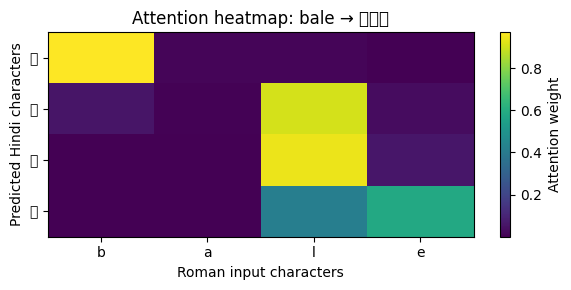

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2369 (\N{DEVANAGARI VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layo

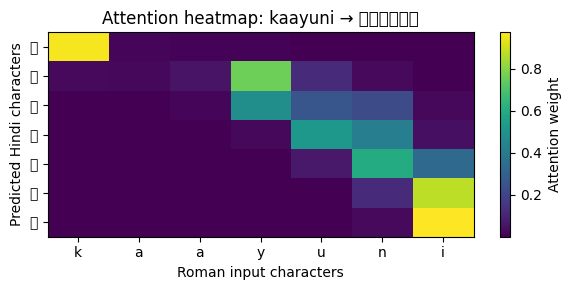

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2379 (\N{DEVANAGARI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from fo

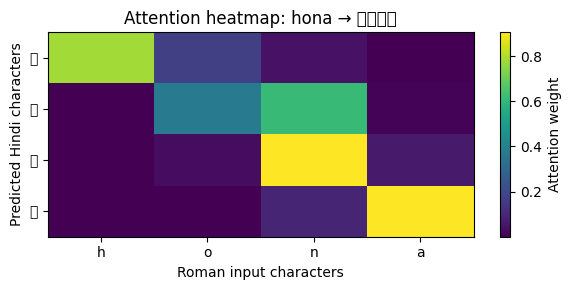

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2309 (\N{DEVANAGARI LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2306 (\N{DEVANAGARI SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplo

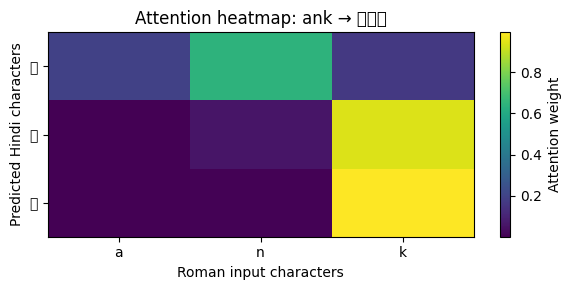

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2360 (\N{DEVANAGARI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2347 (\N{DEVANAGARI LETTER PHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout

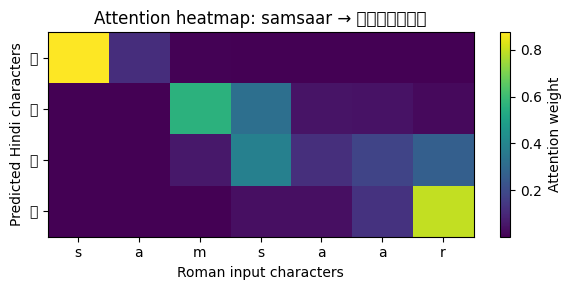

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2348 (\N{DEVANAGARI LETTER BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2340 (\N{DEVANAGARI LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) D

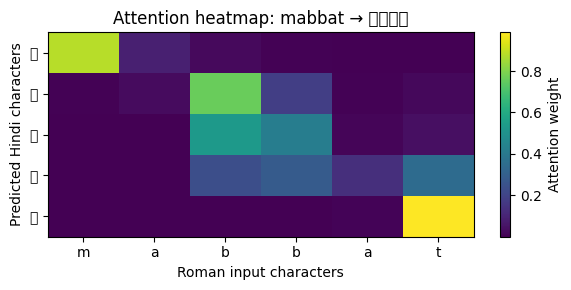

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2306 (\N{DEVANAGARI SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2370 (\N{DEVANAGARI VOWEL SIGN UU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2379 (\N{DEVANAGARI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_lay

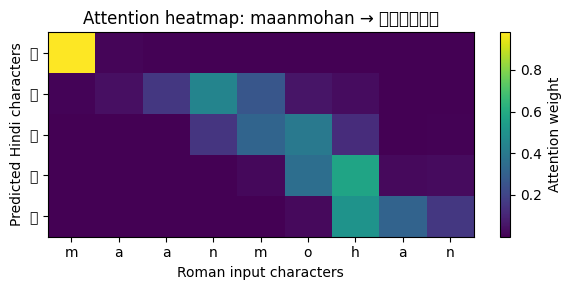

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2313 (\N{DEVANAGARI LETTER U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2310 (\N{DEVANAGARI LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2313 (\N{DEVANAGARI LETTER U}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/

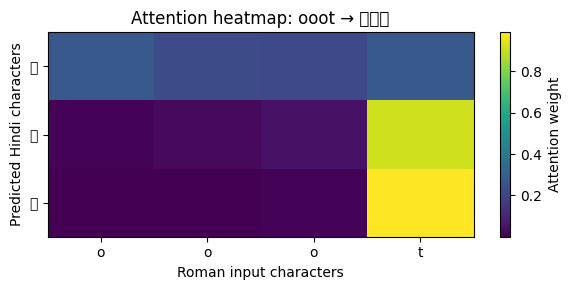

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2340 (\N{DEVANAGARI LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2370 (\N{DEVANAGARI VOWEL SIGN UU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2381 (\N{DEVANAGARI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layo

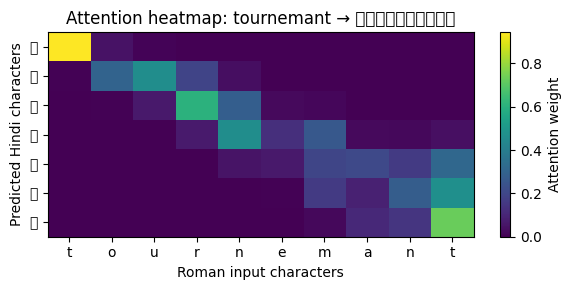

/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2375 (\N{DEVANAGARI VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2330 (\N{DEVANAGARI LETTER CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1339/3971631646.py:27: UserWarning: Glyph 2376 (\N{DEVANAGARI VOWEL SIGN AI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(

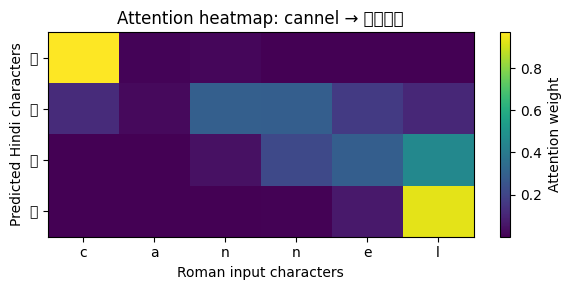

In [12]:
# Attention heatmaps for 10 test examples
# The model uses teacher forcing ratio 0.0 here, so it generates greedily
# for the target sequence length while recording encoder attention weights.
def show_attention_heatmaps(model, pairs, n=10):
    model.eval()
    n = min(n, len(pairs))
    for i in range(n):
        roman, hindi = pairs[i]
        X = torch.tensor([encode_src(roman)], dtype=torch.long, device=DEVICE)
        Y = torch.tensor([encode_tgt(hindi)], dtype=torch.long, device=DEVICE)
        with torch.no_grad():
            logits, weights = model(X, Y, teacher_forcing=0.0, return_attention=True)
        pred_ids = model.predict_ids(X)[0]
        pred_chars = [tgt_ivocab.get(idx, "") for idx in pred_ids]
        source_chars = list(roman)
        target_chars = pred_chars[:weights.shape[1]]
        matrix = weights[0, :len(target_chars), :len(source_chars)].cpu().numpy()

        plt.figure(figsize=(max(6, len(source_chars)*0.45), max(3, len(target_chars)*0.35)))
        plt.imshow(matrix, aspect="auto", cmap="viridis")
        plt.xticks(range(len(source_chars)), source_chars)
        plt.yticks(range(len(target_chars)), target_chars)
        plt.xlabel("Roman input characters")
        plt.ylabel("Predicted Hindi characters")
        plt.title(f"Attention heatmap: {roman} → {hindi}")
        plt.colorbar(label="Attention weight")
        plt.tight_layout()
        plt.show()

show_attention_heatmaps(attention_model, test_pairs, n=10)